# Telco churn: prediction model

This notebook trains and checks the churn models defined in `src/model.py`. It runs the model fitting live (about a minute), and reads the slower tables (bootstrap odds ratios, permutation importance, risk tiers) that `python run_project.py` saved in `reports/tables/model/`. Run `python run_project.py` first so `data/processed/churn_clean.csv` exists.

The data is a sample dataset, so results describe this dataset only. The models show predictive signal and associations, not causes.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent / 'src'))
import model as m
from config import FIGURES_DIR, TABLES_DIR

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
MODEL_TABLES = TABLES_DIR / 'model'
df = m.load_clean()
df['churned'].agg(['size', 'sum', 'mean'])

size    7043.00000
sum     1869.00000
mean       0.26537
Name: churned, dtype: float64

## 1. Features and split

Excluded: the id and target columns, columns that repeat other columns (`total_charges`, `tenure_group`, `is_new_customer`, `addon_services`) and `monthly_charges`, which the service columns explain almost completely. "No internet service" and "No phone service" are merged into "No" for the add-on columns, because `internet_service` and `phone_service` already carry that information.

In [2]:
pd.read_csv(MODEL_TABLES / 'feature_decisions.csv')

,feature,decision,reason
0,customer_id,excluded,identifier
1,churn,excluded,target (text version)
2,churned,excluded,target
3,total_charges,excluded,"about tenure x monthly charges, so mostly a co..."
4,monthly_charges,excluded,99.9% explained by the service columns (R-squa...
5,tenure_group,excluded,tenure_months cut into bands
6,is_new_customer,excluded,tenure_months = 0
7,addon_services,excluded,count of the six add-on columns
8,tenure_months,"used (numeric, scaled)",NaN
9,gender,"used (one-hot, reference: Female)",NaN


In [3]:
pd.read_csv(MODEL_TABLES / 'feature_sensitivity.csv')

,logistic_regression_features,value
0,tenure + categorical (used),0.839449
1,+ total_charges,0.842522
2,+ monthly_charges,0.839324
3,+ both,0.842233
4,R-squared of monthly_charges on the used featu...,0.998837


Adding `total_charges` or `monthly_charges` changes the test ROC-AUC of the logistic regression by at most about 0.003, so leaving them out costs almost nothing and keeps the odds ratios readable.

The split is 80/20, stratified on churn, with a fixed random seed. All fitting, tuning and scaling uses the training part only (they sit inside a scikit-learn Pipeline).

In [4]:
X_tr, X_te, y_tr, y_te = m.split_data(df)
pd.DataFrame({'customers': [len(y_tr), len(y_te)], 'churn_rate_pct': [100 * y_tr.mean(), 100 * y_te.mean()]},
             index=['train', 'test']).round(2)

,customers,churn_rate_pct
train,5634,26.54
test,1409,26.54


## 2. Models, tuning and cross-validation

Three models: a baseline that always predicts "stayed", logistic regression, and gradient boosting. Each has a small tuning grid, scored by ROC-AUC with stratified 5-fold cross-validation on the training set.

In [5]:
fitted, cv_table, grid_table, cv = m.fit_models(X_tr, y_tr)
grid_table.round(4)

,model,parameters,cv_roc_auc_mean,cv_roc_auc_std,chosen
0,Logistic regression,{'model__C': 0.01},0.8424,0.0122,0
1,Logistic regression,{'model__C': 0.1},0.8447,0.0121,0
2,Logistic regression,{'model__C': 1},0.8448,0.0121,0
3,Logistic regression,{'model__C': 10},0.8448,0.0121,1
4,Gradient boosting,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8474,0.0131,0
5,Gradient boosting,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8495,0.0122,1
6,Gradient boosting,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8493,0.0110,0
7,Gradient boosting,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8488,0.0111,0
8,Gradient boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.8495,0.0122,0
9,Gradient boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.8483,0.0123,0


## 3. Held-out test results

Accuracy alone misleads here: the baseline never finds a single churner but is right 73.5% of the time, because 73.5% of customers stay. ROC-AUC and PR-AUC (average precision) do not have that problem. The precision, recall and F1 columns use the default threshold of 0.5.

In [6]:
scores = m.test_scores(fitted, X_te)
comparison = m.evaluate(scores, y_te, cv_table)
comparison.round(3)

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std,test_roc_auc,test_pr_auc,accuracy,precision,recall,f1,true_positive,false_positive,false_negative,true_negative,customers_flagged
0,Baseline (always predicts stayed),0.500,0.000,0.265,0.000,0.500,0.265,0.735,0.000,0.000,0.000,0,0,374,1035,0
1,Logistic regression,0.845,0.012,0.659,0.019,0.839,0.630,0.797,0.636,0.551,0.590,206,118,168,917,324
2,Gradient boosting,0.850,0.012,0.666,0.022,0.846,0.659,0.804,0.670,0.516,0.583,193,95,181,940,288


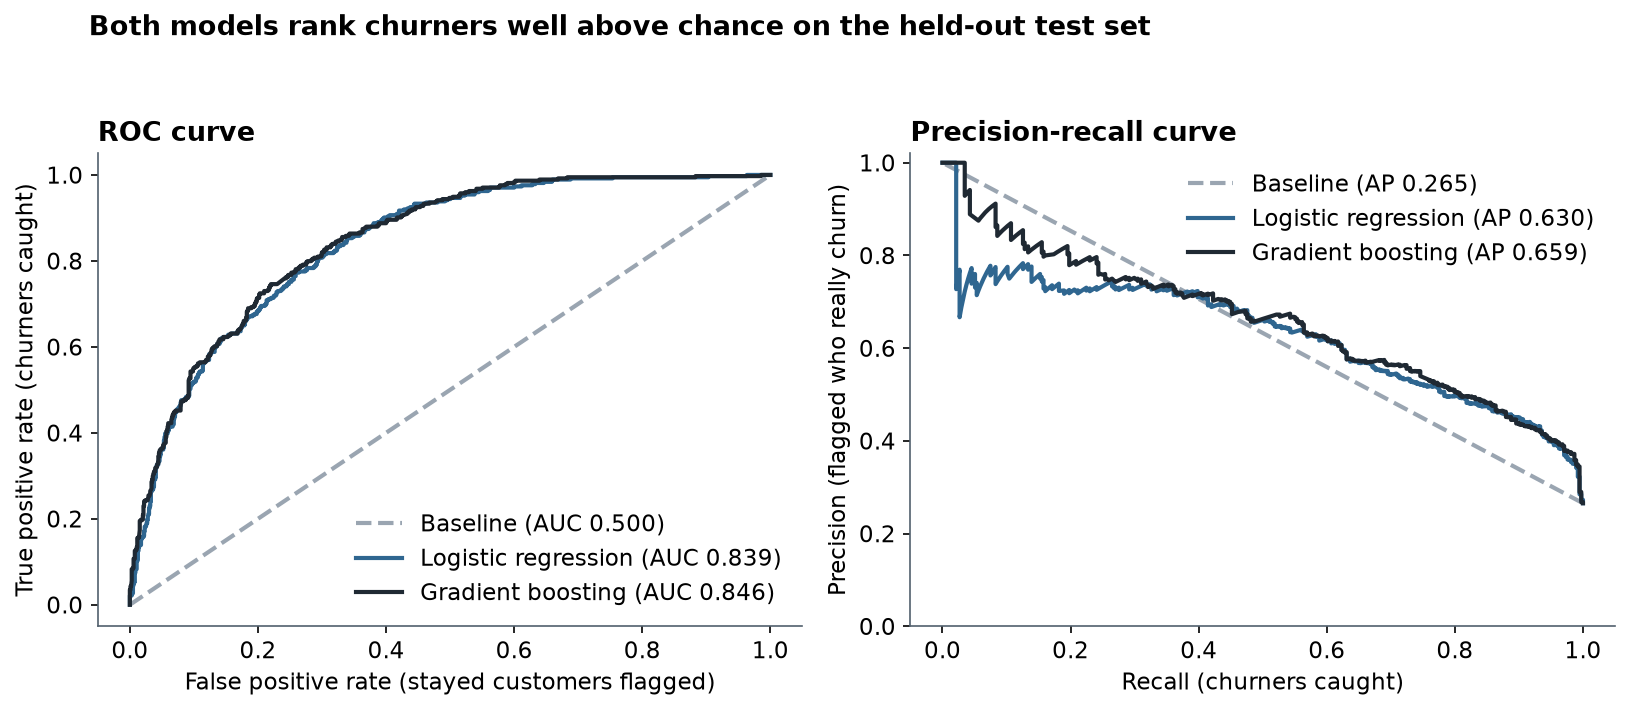

In [7]:
display(Image(FIGURES_DIR / '07_roc_and_pr_curves.png', width=800))

Gradient boosting is slightly ahead of logistic regression on the test set, but the gap in cross-validated ROC-AUC is well inside one standard deviation. The rule in `m.choose_final_model` therefore keeps logistic regression, the simpler and more readable model.

In [8]:
m.choose_final_model(cv_table)

'Logistic regression'

## 4. Threshold

The model gives each customer a churn probability. The threshold turns that into "flag / do not flag". It is chosen on the training set only: the highest threshold whose out-of-fold recall is at least 70%, because the assumed action (a low-cost retention offer) is cheap compared with losing a customer.

In [9]:
final = fitted[m.LOGREG]
threshold, train_thresholds = m.choose_threshold(final, X_tr, y_tr, cv)
threshold

0.35

In [10]:
m.threshold_table(scores[m.LOGREG], y_te, threshold).round(3)[['threshold', 'precision', 'recall', 'f1', 'customers_flagged', 'flagged_pct_of_customers', 'chosen']]

,threshold,precision,recall,f1,customers_flagged,flagged_pct_of_customers,chosen
0,0.05,0.356,0.981,0.523,1030,73.101,0
1,0.10,0.403,0.947,0.565,879,62.385,0
2,0.15,0.440,0.909,0.593,773,54.862,0
3,0.20,0.470,0.856,0.607,681,48.332,0
4,0.25,0.497,0.786,0.609,592,42.016,0
5,0.30,0.523,0.741,0.613,530,37.615,0
6,0.35,0.544,0.706,0.615,485,34.422,1
7,0.40,0.568,0.666,0.613,438,31.086,0
8,0.45,0.611,0.610,0.610,373,26.473,0
9,0.50,0.636,0.551,0.590,324,22.995,0


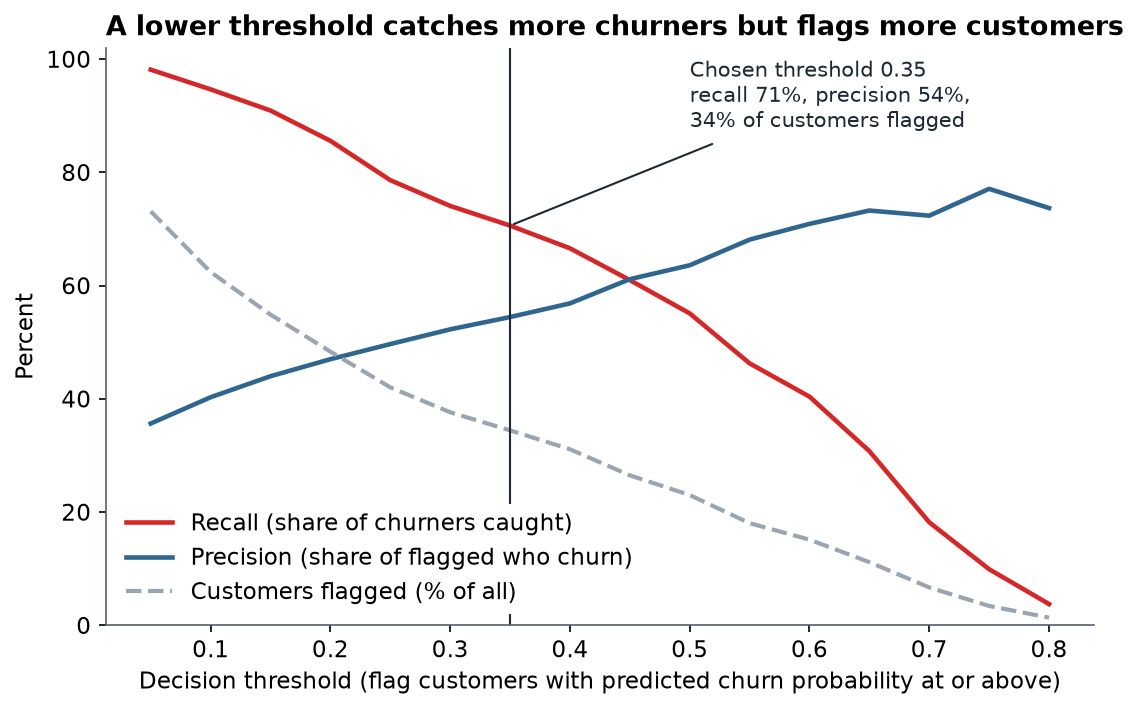

In [11]:
display(Image(FIGURES_DIR / '08_threshold_tradeoff.png', width=700))

## 5. Calibration and lift

Customers in the test set are sorted by predicted probability and cut into ten equal groups. If the model is well calibrated, the actual churn rate in each group is close to the average predicted probability.

In [12]:
m.decile_table(y_te, scores[m.LOGREG]).round(3)

,decile,customers,churned,avg_predicted_churn,actual_churn_rate,lift,cum_customers_pct,cum_churners_captured_pct
0,1,141,103,0.734,0.730,2.752,10.007,27.540
1,2,141,83,0.597,0.589,2.218,20.014,49.733
2,3,141,56,0.470,0.397,1.496,30.021,64.706
3,4,141,48,0.339,0.340,1.283,40.028,77.540
4,5,141,36,0.226,0.255,0.962,50.035,87.166
5,6,141,24,0.148,0.170,0.641,60.043,93.583
6,7,141,14,0.086,0.099,0.374,70.050,97.326
7,8,141,7,0.046,0.050,0.187,80.057,99.198
8,9,141,1,0.023,0.007,0.027,90.064,99.465
9,10,140,2,0.008,0.014,0.054,100.000,100.000


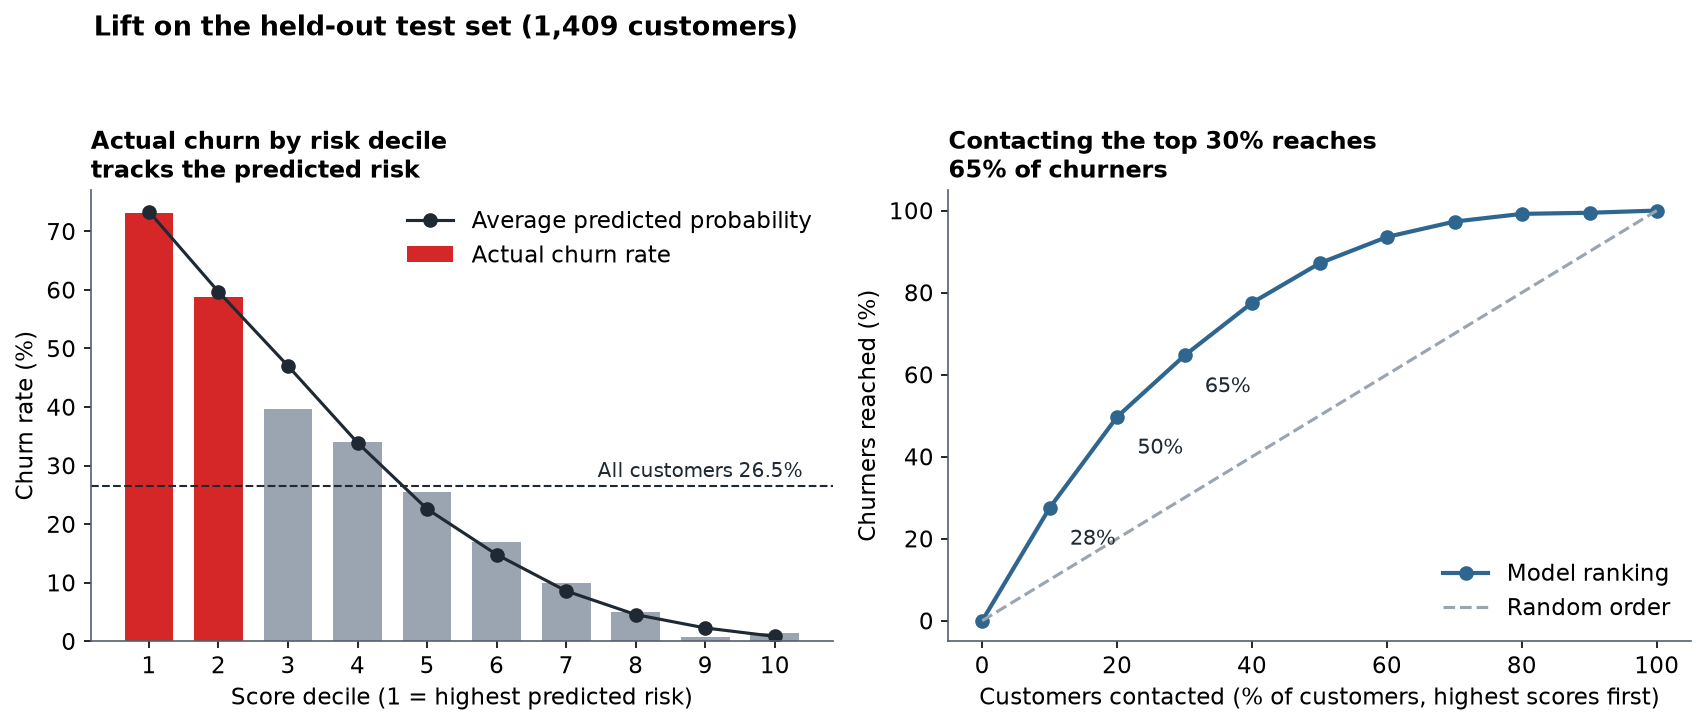

In [13]:
display(Image(FIGURES_DIR / '10_lift_and_calibration.png', width=800))

## 6. What drives the predictions

Odds ratios come from the logistic regression (each compared with the stated reference group, other features held fixed). Permutation importance shows how much the test ROC-AUC of the gradient boosting model drops when one feature is shuffled.

In [14]:
pd.read_csv(MODEL_TABLES / 'logistic_odds_ratios.csv').round(2).head(12)

,feature,level,compared_with,odds_ratio,ci_low,ci_high
0,contract,Two year,Month-to-month,0.26,0.18,0.36
1,internet_service,Fiber optic,DSL,2.50,2.08,3.11
2,internet_service,No,DSL,0.44,0.32,0.60
3,tenure_months,per +1 SD (24.6),average customer,0.45,0.39,0.50
4,contract,One year,Month-to-month,0.49,0.40,0.60
5,phone_service,Yes,No,0.63,0.46,0.84
6,online_security,Yes,No,0.68,0.58,0.79
7,payment_method,Electronic check,Bank transfer (automatic),1.46,1.20,1.78
8,paperless_billing,Yes,No,1.45,1.27,1.71
9,tech_support,Yes,No,0.71,0.59,0.87


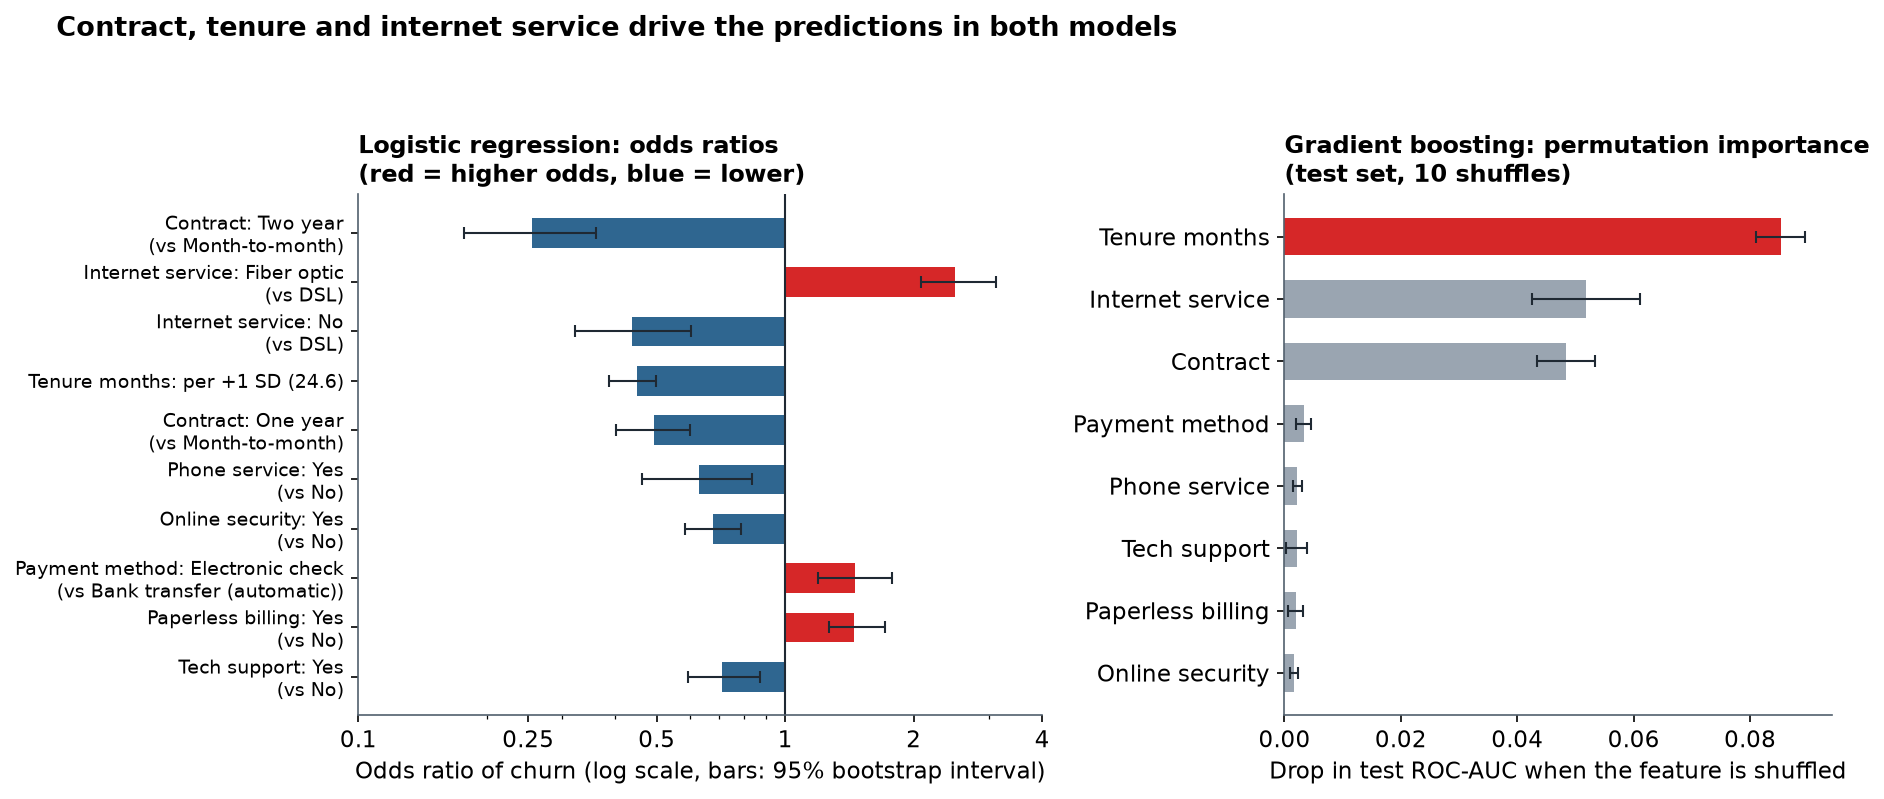

In [15]:
display(Image(FIGURES_DIR / '09_top_drivers.png', width=900))

The same three features, contract, tenure and internet service, come out on top in both models, in line with the exploratory results. Odds ratios are associations, not effects of changing a customer's contract.

## 7. Risk tiers for current customers

Every customer is scored by a model that did not see them (out-of-fold). Only customers who had not churned are tiered. "Expected monthly charges at risk" is the sum of monthly charges times predicted churn probability: an estimate that assumes calibrated probabilities, not a forecast and not lifetime value.

In [16]:
pd.read_csv(MODEL_TABLES / 'risk_tiers_current_customers.csv').round(2)

,tier,customers,avg_predicted_churn,monthly_charges,expected_monthly_charges_at_risk,share_of_customers_pct,share_of_expected_at_risk_pct
0,High,997,0.53,76354.95,41288.68,19.27,60.83
1,Medium,959,0.25,61003.05,15609.60,18.53,23.00
2,Low,3218,0.06,179627.75,10971.70,62.20,16.17


In [17]:
pd.read_csv(MODEL_TABLES / 'business_assumptions.csv')['assumption'].tolist()

['Scores for all 7,043 customers are out-of-fold: each customer is scored by a model fitted on other customers.',
 'Only customers with churned = 0 are tiered. In this snapshot they are the customers who had not left.',
 'High tier: predicted churn probability at or above 0.35 (the chosen threshold). Medium: 0.175 to below 0.35. Low: below 0.175.',
 'Expected monthly charges at risk = sum of monthly_charges x predicted churn probability. It assumes the probabilities are well calibrated and is an estimate, not a forecast.',
 'It is a monthly bill, not lifetime value or profit, and the data has no dates, so it says nothing about when customers would leave.',
 'Sample dataset: the figures describe this dataset, not a real company.']